In [11]:
import random
import numpy as np
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [12]:
import pandas as pd

actions = pd.read_csv(
    "SHS148k.actions.txt",
    sep="\t"
)

print(actions.head())

print(actions.columns)

              item_id_a             item_id_b        mode      action  \
0  9606.ENSP00000000233  9606.ENSP00000263025       ptmod         NaN   
1  9606.ENSP00000000233  9606.ENSP00000265709    reaction         NaN   
2  9606.ENSP00000000233  9606.ENSP00000265709   catalysis         NaN   
3  9606.ENSP00000000233  9606.ENSP00000263025  inhibition  inhibition   
4  9606.ENSP00000000233  9606.ENSP00000265709     binding         NaN   

  is_directional a_is_acting  score  
0              f           f    150  
1              f           f    908  
2              t           t    908  
3              t           t    154  
4              f           t    908  
Index(['item_id_a', 'item_id_b', 'mode', 'action', 'is_directional',
       'a_is_acting', 'score'],
      dtype='object')


In [13]:
print(actions.shape)

print(actions["mode"].value_counts().head(20))

(369042, 7)
mode
reaction      102964
binding        93632
catalysis      67168
activation     42516
inhibition     34712
ptmod          20154
expression      7896
Name: count, dtype: int64


In [14]:
positive_df = actions[
    ["item_id_a", "item_id_b"]
].copy()

positive_df.columns = [
    "protein1",
    "protein2"
]

positive_df["label"] = 1

print(positive_df.shape)

positive_df.head()

(369042, 3)


,protein1,protein2,label
0,9606.ENSP00000000233,9606.ENSP00000263025,1
1,9606.ENSP00000000233,9606.ENSP00000265709,1
2,9606.ENSP00000000233,9606.ENSP00000265709,1
3,9606.ENSP00000000233,9606.ENSP00000263025,1
4,9606.ENSP00000000233,9606.ENSP00000265709,1


In [15]:
positive_df = positive_df.drop_duplicates()

print(positive_df.shape)

(88976, 3)


In [16]:
positive_df[["protein1","protein2"]] = (
    positive_df.apply(
        lambda x: sorted([x["protein1"], x["protein2"]]),
        axis=1,
        result_type="expand"
    )
)

positive_df = positive_df.drop_duplicates(
    subset=["protein1","protein2"]
).reset_index(drop=True)

In [17]:
seqs = pd.read_csv(
    "SHS148k.seqs.tsv",
    sep="\t",
    header=None
)

seqs.columns = [
    "protein",
    "sequence"
]

print(seqs.head())

print(seqs.shape)

                protein                                           sequence
0  9606.ENSP00000000233  MGLTVSALFSRIFGKKQMRILMVGLDAAGKTTILYKLKLGEIVTTI...
1  9606.ENSP00000263025  MAAAAAQGGGGGEPRRTEGVGPGVPGEVEMVKGQPFDVGPRYTQLQ...
2  9606.ENSP00000265709  MAQAAKQLKKIKDIEAQALQEQKEKEESNRKRRNRSRDRKKKADAA...
3  9606.ENSP00000250971  MALWMRLLPLLALLALWGPDPAAAFVNQHLCGSHLVEALYLVCGER...
4  9606.ENSP00000265382  MSSAAENGEAAPGKQNEEKTYKKTASSAIKGAIQLGIGYTVGNLTS...
(5189, 2)


In [18]:
protein_sequences = dict(
    zip(
        seqs["protein"],
        seqs["sequence"]
    )
)

print(
    "Sequences:",
    len(protein_sequences)
)

proteins = set(
    positive_df["protein1"]
).union(
    set(
        positive_df["protein2"]
    )
)

print(
    "Proteins in interactions:",
    len(proteins)
)

print(
    "Found sequences:",
    sum(
        p in protein_sequences
        for p in proteins
    )
)

Sequences: 5189
Proteins in interactions: 5189
Found sequences: 5189


In [19]:
import random

positive_pairs = set()

for _, row in positive_df.iterrows():

    p1 = row["protein1"]
    p2 = row["protein2"]

    positive_pairs.add(
        tuple(sorted([p1, p2]))
    )

proteins = list(
    protein_sequences.keys()
)

negative_pairs = set()

while len(negative_pairs) < len(positive_df):

    p1 = random.choice(proteins)
    p2 = random.choice(proteins)

    if p1 == p2:
        continue

    pair = tuple(
        sorted([p1, p2])
    )

    if pair in positive_pairs:
        continue

    negative_pairs.add(pair)

negative_df = pd.DataFrame(
    list(negative_pairs),
    columns=["protein1","protein2"]
)

negative_df["label"] = 0

print(negative_df.shape)

(44488, 3)


In [20]:
ppi_df = pd.concat(
    [
        positive_df,
        negative_df
    ],
    ignore_index=True
)
ppi_df.to_csv(
    "shs148k_full_seed42_balanced.csv",
    index=False
)
print(
    ppi_df["label"].value_counts()
)

print(ppi_df.shape)

label
1    44488
0    44488
Name: count, dtype: int64
(88976, 3)


In [21]:
from sklearn.model_selection import train_test_split

# Canonical representation of pairs
ppi_df["protein1"], ppi_df["protein2"] = zip(
    *ppi_df.apply(
        lambda x: sorted([x["protein1"], x["protein2"]]),
        axis=1
    )
)

ppi_df = ppi_df.drop_duplicates(
    subset=["protein1","protein2"]
).reset_index(drop=True)

train_df, test_df = train_test_split(
    ppi_df,
    test_size=0.20,
    stratify=ppi_df["label"],
    random_state=SEED
)

train_df, valid_df = train_test_split(
    train_df,
    test_size=0.10,
    stratify=train_df["label"],
    random_state=SEED
)

print(train_df.shape)
print(valid_df.shape)
print(test_df.shape)

(64062, 3)
(7118, 3)
(17796, 3)


In [22]:
proteins = set(
    train_df["protein1"]
).union(
    set(train_df["protein2"])
).union(
    set(valid_df["protein1"])
).union(
    set(valid_df["protein2"])
).union(
    set(test_df["protein1"])
).union(
    set(test_df["protein2"])
)

unique_proteins = pd.DataFrame(
    {
        "protein": list(proteins)
    }
)

unique_proteins["sequence"] = (
    unique_proteins["protein"]
    .map(protein_sequences)
)

unique_proteins = unique_proteins.dropna()

print(unique_proteins.shape)

(5189, 2)


In [23]:
!pip install fair-esm

In [24]:
import esm
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

model, alphabet = (
    esm.pretrained.esm2_t6_8M_UR50D()
)

model = model.to(device)

model.eval()

batch_converter = (
    alphabet.get_batch_converter()
)

print(device)

cuda


In [25]:
import numpy as np

@torch.no_grad()
def get_embedding(sequence):

    sequence = sequence[:1022]

    data = [
        (
            "protein",
            sequence
        )
    ]

    _, _, tokens = (
        batch_converter(data)
    )

    tokens = tokens.to(device)

    results = model(
        tokens,
        repr_layers=[6],
        return_contacts=False
    )

    token_embeddings = (
        results["representations"][6]
    )

    embedding = (
        token_embeddings[0,1:-1]
        .mean(0)
    )

    return embedding.cpu().numpy()

In [26]:

from tqdm import tqdm

protein_embeddings = {}

for _, row in tqdm(
    unique_proteins.iterrows(),
    total=len(unique_proteins)
):

    protein_id = row["protein"]

    sequence = row["sequence"]

    protein_embeddings[
        protein_id
    ] = get_embedding(
        sequence
    )

print(
    len(protein_embeddings)
)

100%|██████████| 5189/5189 [01:32<00:00, 55.80it/s]

5189


In [27]:
print(len(protein_embeddings))

5189


In [28]:
valid_proteins = set(
    protein_embeddings.keys()
)

train_df = train_df[
    train_df["protein1"].isin(valid_proteins)
    &
    train_df["protein2"].isin(valid_proteins)
].reset_index(drop=True)

valid_df = valid_df[
    valid_df["protein1"].isin(valid_proteins)
    &
    valid_df["protein2"].isin(valid_proteins)
].reset_index(drop=True)

test_df = test_df[
    test_df["protein1"].isin(valid_proteins)
    &
    test_df["protein2"].isin(valid_proteins)
].reset_index(drop=True)

print(train_df.shape)
print(valid_df.shape)
print(test_df.shape)

(64062, 3)
(7118, 3)
(17796, 3)


In [29]:
train_df.to_csv("train_shs148k_seed42.csv", index=False)
valid_df.to_csv("valid_shs148k_seed42.csv", index=False)
test_df.to_csv("test_shs148k_seed42.csv", index=False)

print("Train/Validation/Test CSV files saved.")

Train/Validation/Test CSV files saved.


In [30]:
def pair_set(df):
    return set(
        tuple(sorted((a, b)))
        for a, b in zip(df.protein1, df.protein2)
    )

train_pairs = pair_set(train_df)
valid_pairs = pair_set(valid_df)
test_pairs = pair_set(test_df)

print("Train ∩ Valid =", len(train_pairs & valid_pairs))
print("Train ∩ Test  =", len(train_pairs & test_pairs))
print("Valid ∩ Test  =", len(valid_pairs & test_pairs))

Train ∩ Valid = 0
Train ∩ Test  = 0
Valid ∩ Test  = 0


In [31]:
import numpy as np
import torch

proteins = list(
    protein_embeddings.keys()
)

protein_to_idx = {
    p:i
    for i,p in enumerate(proteins)
}

X = np.array(
    [protein_embeddings[p]
     for p in proteins],
    dtype=np.float32
)

x = torch.tensor(X)

print(x.shape)

torch.Size([5189, 320])


In [32]:
positive_train = train_df[
    train_df["label"] == 1
]

print(positive_train.shape)

(32031, 3)


In [33]:
from collections import defaultdict

neighbors = defaultdict(set)

for _, row in positive_train.iterrows():

    p1 = row["protein1"]
    p2 = row["protein2"]

    neighbors[p1].add(p2)
    neighbors[p2].add(p1)

print(len(neighbors))

4868


In [34]:
hyperedges = []

for protein in neighbors:

    members = set()

    members.add(protein)

    members.update(
        neighbors[protein]
    )

    hyperedges.append(
        list(members)
    )

print(len(hyperedges))

4868


In [35]:

node_ids = []
edge_ids = []

for edge_id, members in enumerate(hyperedges):

    for protein in members:

        if protein in protein_to_idx:

            node_ids.append(
                protein_to_idx[protein]
            )

            edge_ids.append(
                edge_id
            )

hyperedge_index = torch.tensor(
    [node_ids, edge_ids],
    dtype=torch.long
)

print(hyperedge_index.shape)

torch.Size([2, 68930])


In [36]:
!pip install torch-geometric
!pip install tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 28.5 MB/s eta 0:00:00


In [37]:
from torch_geometric.data import Data

graph = Data(
    x=x,
    hyperedge_index=hyperedge_index
)

print(graph)

Data(x=[5189, 320], hyperedge_index=[2, 68930])


In [38]:
graph = graph.to(device)

print(graph.x.device)
print(graph.hyperedge_index.device)

cuda:0
cuda:0


In [39]:
train_pairs = []

for _, row in train_df.iterrows():

    train_pairs.append(
        (
            protein_to_idx[row["protein1"]],
            protein_to_idx[row["protein2"]],
            row["label"]
        )
    )

valid_pairs = []

for _, row in valid_df.iterrows():

    valid_pairs.append(
        (
            protein_to_idx[row["protein1"]],
            protein_to_idx[row["protein2"]],
            row["label"]
        )
    )

test_pairs = []

for _, row in test_df.iterrows():

    test_pairs.append(
        (
            protein_to_idx[row["protein1"]],
            protein_to_idx[row["protein2"]],
            row["label"]
        )
    )

print(len(train_pairs))
print(len(valid_pairs))
print(len(test_pairs))

64062
7118
17796


In [40]:
from torch.utils.data import Dataset

class PPIDataset(Dataset):

    def __init__(self,data):

        self.data=data

    def __len__(self):

        return len(self.data)

    def __getitem__(self,idx):

        p1,p2,y=self.data[idx]

        return (

            torch.tensor(p1),

            torch.tensor(p2),

            torch.tensor(y,dtype=torch.float32)

        )

In [41]:
from torch.utils.data import DataLoader

train_dataset = PPIDataset(
    train_pairs
)

valid_dataset = PPIDataset(
    valid_pairs
)

test_dataset = PPIDataset(
    test_pairs
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=128,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

In [42]:
from torch_geometric.nn import HypergraphConv
import torch
import torch.nn as nn
import torch.nn.functional as F


class HGNNEncoder(nn.Module):

    def __init__(self):
        super().__init__()

        self.protein_encoder = nn.Sequential(

            nn.Linear(320,512),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(512,320)

        )

        self.h1 = HypergraphConv(320,512)

        self.h2 = HypergraphConv(512,256)

        self.h3 = HypergraphConv(256,128)


    def forward(self,x,hyperedge_index):

        residual = x

        x = self.protein_encoder(x)

        x = x + residual

        x = self.h1(
            x,
            hyperedge_index
        )

        x = F.relu(x)

        x = self.h2(
            x,
            hyperedge_index
        )

        x = F.relu(x)

        x = self.h3(
            x,
            hyperedge_index
        )

        return x



class ESM2_HGNN_CrossAttention_MLP(nn.Module):

    def __init__(self):

        super().__init__()

        self.hgnn = HGNNEncoder()

        self.input_proj = nn.Linear(
            448,
            256
        )
        self.attention = nn.MultiheadAttention(
          embed_dim=256,
          num_heads=8,
          batch_first=True
      )

        self.classifier = nn.Sequential(

          nn.Linear(
              1024,
              512
          ),

          nn.ReLU(),

          nn.Dropout(0.3),

          nn.Linear(
             512,
             128
          ),

          nn.ReLU(),

          nn.Dropout(0.3),

          nn.Linear(
              128,
             1
          )

      )


    def forward(self,p1_idx,p2_idx,graph_x,hyperedge_index):

        hgnn_emb = self.hgnn(
            graph_x,
            hyperedge_index
        )

        final_emb = torch.cat(
            [
                graph_x,
                hgnn_emb
            ],
            dim=1
        )

        p1 = final_emb[p1_idx]
        p2 = final_emb[p2_idx]

        p1 = self.input_proj(p1)
        p2 = self.input_proj(p2)
        attn_out, _ = self.attention(

          p1.unsqueeze(1),

          p2.unsqueeze(1),

          p2.unsqueeze(1)

        )

        attn_out = attn_out.squeeze(1)
        features = torch.cat(

    [

        p1,
        p2,
        torch.abs(p1-p2),
        attn_out

    ],

    dim=1

)

        return self.classifier(
            features
        ).squeeze()



device = torch.device(

    "cuda" if torch.cuda.is_available()
    else "cpu"

)

model = ESM2_HGNN_CrossAttention_MLP().to(device)

criterion = nn.BCEWithLogitsLoss()

optimizer = torch.optim.Adam(

    model.parameters(),

    lr=1e-3

)

In [43]:
!pip install thop

In [44]:
from sklearn.metrics import roc_auc_score
from tqdm import tqdm
import torch

best_auc = 0
counter = 0

EPOCHS = 20

for epoch in range(EPOCHS):

    model.train()

    total_loss = 0

    for p1, p2, y in tqdm(train_loader):

        p1 = p1.to(device)
        p2 = p2.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        logits = model(
            p1,
            p2,
            graph.x,
            graph.hyperedge_index
        )

        loss = criterion(
            logits,
            y
        )

        loss.backward()

        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch+1}",
        total_loss / len(train_loader)
    )

    model.eval()

    valid_probs = []
    valid_labels = []

    with torch.no_grad():

        for p1, p2, y in valid_loader:

            p1 = p1.to(device)
            p2 = p2.to(device)

            logits = model(
                p1,
                p2,
                graph.x,
                graph.hyperedge_index
            )

            prob = torch.sigmoid(
                logits
            )

            valid_probs.extend(
                prob.cpu().numpy()
            )

            valid_labels.extend(
                y.numpy()
            )

    valid_auc = roc_auc_score(
        valid_labels,
        valid_probs
    )

    print(
        "Validation AUC:",
        valid_auc
    )

    if valid_auc > best_auc:

        best_auc = valid_auc

        torch.save(
            model.state_dict(),
            "STUDY3_shs148k.pth"
        )

        counter = 0

        print(
            "New best model saved"
        )

    else:

        counter += 1

        if counter >= 5:

            print(
                "Early stopping"
            )

            break

print(
    "Best Validation AUC:",
    best_auc
)

model.load_state_dict(
    torch.load("STUDY3_shs148k.pth")
)
from thop import profile

p1, p2, _ = next(iter(test_loader))

p1 = p1.to(device)
p2 = p2.to(device)

flops, params = profile(
    model,
    inputs=(p1, p2, graph.x, graph.hyperedge_index),
    verbose=False
)

print("="*50)
print("MODEL COMPUTATIONAL COMPLEXITY")
print("="*50)
print(f"FLOPs      : {flops:,}")
print(f"Parameters : {params:,}")

100%|██████████| 501/501 [00:24<00:00, 20.71it/s]


Epoch 1 0.2951883402413237
Validation AUC: 0.9272843025620139
New best model saved


100%|██████████| 501/501 [00:17<00:00, 28.47it/s]


Epoch 2 0.2195813924579801
Validation AUC: 0.931927896943121
New best model saved


100%|██████████| 501/501 [00:17<00:00, 28.43it/s]


Epoch 3 0.19524669351275573
Validation AUC: 0.935012810582513
New best model saved


... (26 outputs left out)

100%|██████████| 501/501 [00:17<00:00, 28.94it/s]


Epoch 17 0.07546777115342859
Validation AUC: 0.9521883386553851


100%|██████████| 501/501 [00:17<00:00, 28.68it/s]


Epoch 18 0.07112243543648553
Validation AUC: 0.9523575648200948
Early stopping
Best Validation AUC: 0.9532824467979701
MODEL COMPUTATIONAL COMPLEXITY
FLOPs      : 1,805,205,504.0
Parameters : 1,034,049.0


In [45]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    f1_score,
    precision_score,
    recall_score,
    matthews_corrcoef,
    average_precision_score,
    confusion_matrix
)

model.eval()

preds = []
probs = []
labels = []

with torch.no_grad():

    for p1, p2, y in test_loader:

        p1 = p1.to(device)
        p2 = p2.to(device)

        logits = model(
            p1,
            p2,
            graph.x,
            graph.hyperedge_index
        )

        prob = torch.sigmoid(
            logits
        )

        pred = (
            prob > 0.5
        ).int()

        probs.extend(
            prob.cpu().numpy()
        )

        preds.extend(
            pred.cpu().numpy()
        )

        labels.extend(
            y.numpy()
        )

acc = accuracy_score(
    labels,
    preds
)

auc = roc_auc_score(
    labels,
    probs
)

f1 = f1_score(
    labels,
    preds
)

precision = precision_score(
    labels,
    preds
)

recall = recall_score(
    labels,
    preds
)

mcc = matthews_corrcoef(
    labels,
    preds
)

aupr = average_precision_score(
    labels,
    probs
)

cm = confusion_matrix(
    labels,
    preds
)

print("Accuracy :", acc)
print("AUC      :", auc)
print("AUPR     :", aupr)
print("F1       :", f1)
print("Precision:", precision)
print("Recall   :", recall)
print("MCC      :", mcc)
print(cm)

Accuracy : 0.9013261407057765
AUC      : 0.9523290570018059
AUPR     : 0.9600680174118184
F1       : 0.8961684011352885
Precision: 0.9455952083853256
Recall   : 0.851652056641942
MCC      : 0.8066429594900506
[[8462  436]
 [1320 7578]]


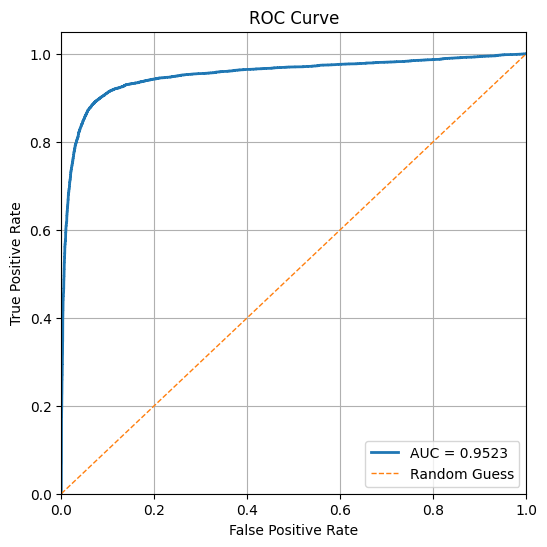

In [46]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt
fpr, tpr, thresholds = roc_curve(
    labels,
    probs
)
plt.figure(figsize=(6,6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUC = {auc:.4f}"
)
plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    linewidth=1,
    label="Random Guess"
)

plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")

plt.legend(loc="lower right")

plt.grid(True)

plt.show()